# Detección de fraude en pagos con tarjeta
**Mateo Taylor** · Proyecto de portfolio · Data Scientist

**Problema:** una fintech pierde dinero con cada fraude que no detecta (el contracargo lo absorbe ella),
pero también pierde cuando bloquea a un cliente legítimo: cada alerta la revisa un analista y cada
bloqueo injusto genera fricción. Hoy usa una **regla fija** (monto alto o compra internacional desde un
dispositivo nuevo). Quiero un modelo que **priorice mejor qué revisar** y elegir el umbral de alerta
según el **costo real** de cada tipo de error, no según el accuracy.

> ⚠️ **Datos simulados** con `generar_datos.py`: 90.000 transacciones (ene–jun 2025) con ~1,2 % de fraude,
> generadas con un modelo de riesgo con interacciones y ruido. No corresponden a ninguna entidad real.

**Contenido**
1. Exploración: ¿dónde está el fraude?
2. Variables y partición temporal
3. Comparación de modelos
4. Umbral óptimo según costo
5. Resultado final en datos nunca vistos
6. ¿Qué mira el modelo?
7. Conclusiones

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

VERDE, LIMA, GRIS, TINTA, ROJO, AZUL, OCRE = "#4f6b00", "#a6cf1f", "#9aa196", "#1d2219", "#c75b46", "#3f9c8f", "#d9a521"
plt.rcParams.update({
    "figure.figsize": (10, 4.2), "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c9cec4",
    "xtick.color": "#5a6253", "ytick.color": "#5a6253", "axes.titleweight": "bold", "axes.titlesize": 13,
    "axes.titlelocation": "left", "axes.titlepad": 12, "axes.grid": True, "grid.color": "#e6e9e1",
    "axes.axisbelow": True, "font.size": 10.5, "legend.frameon": False,
})
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
SEED = 42

tx = pd.read_csv("data/transacciones.csv.gz", parse_dates=["fecha_hora"])
print(f"{len(tx):,} transacciones · {tx['fraude'].sum():,} fraudes ({tx['fraude'].mean():.2%}) · "
      f"US$ {tx.loc[tx['fraude'] == 1, 'monto_usd'].sum():,.0f} en montos fraudulentos")
tx.head()

90,000 transacciones · 1,086 fraudes (1.21%) · US$ 309,615 en montos fraudulentos


,transaccion_id,fecha_hora,cliente_id,monto_usd,categoria_comercio,canal,internacional,distancia_domicilio_km,dispositivo_nuevo,tx_ultimas_24h,intentos_fallidos_previos,gasto_medio_30d_usd,antiguedad_cuenta_dias,edad_titular,fraude
0,X0011131,2025-01-01 00:05:00,T01746,5.350,Gastronomía,contactless,False,12.500,False,4,1,29.910,2054,67,0
1,X0048977,2025-01-01 00:08:00,T03574,97.620,Electrónica,contactless,False,3.100,False,2,0,8.800,281,40,0
2,X0029290,2025-01-01 00:16:00,T06171,19.850,Suscripciones digitales,online,True,0.000,False,1,0,75.950,870,66,0
3,X0045167,2025-01-01 00:19:00,T03356,118.490,Combustible,contactless,False,13.700,False,1,0,111.920,1033,25,0
4,X0010198,2025-01-01 00:20:00,T04309,70.170,Supermercado,presencial,False,7.500,False,1,0,22.080,1486,54,0


## 1. Exploración: ¿dónde está el fraude?
Con un 1,2 % de casos positivos, un modelo que diga "nunca es fraude" tendría 98,8 % de accuracy y no
serviría para nada. Por eso miro **tasas de fraude por segmento** y, más adelante, métricas pensadas para
clases desbalanceadas.

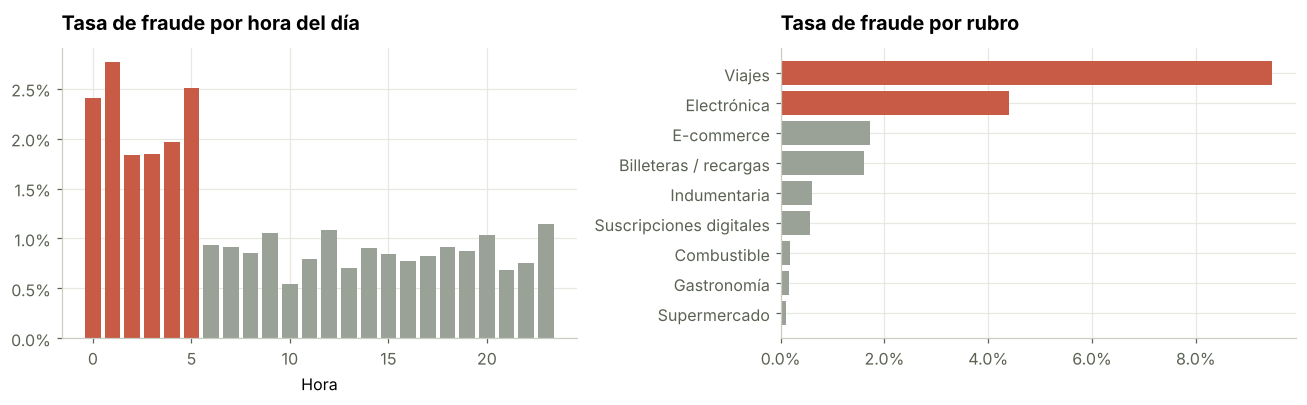

In [2]:
tx["hora"] = tx["fecha_hora"].dt.hour
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
h = tx.groupby("hora")["fraude"].mean()
axes[0].bar(h.index, h.values, color=[ROJO if x < 6 else GRIS for x in h.index])
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=1)); axes[0].set_title("Tasa de fraude por hora del día")
axes[0].set_xlabel("Hora")
c = tx.groupby("categoria_comercio")["fraude"].mean().sort_values()
axes[1].barh(c.index, c.values, color=[ROJO if v > .02 else GRIS for v in c.values])
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=1)); axes[1].set_title("Tasa de fraude por rubro")
plt.tight_layout(); plt.show()

In [3]:
seg = pd.DataFrame({
    "tasa_de_fraude": [tx["fraude"].mean(),
                       tx.loc[tx["internacional"], "fraude"].mean(),
                       tx.loc[tx["dispositivo_nuevo"], "fraude"].mean(),
                       tx.loc[tx["antiguedad_cuenta_dias"] < 60, "fraude"].mean(),
                       tx.loc[tx["tx_ultimas_24h"] >= 6, "fraude"].mean(),
                       tx.loc[tx["intentos_fallidos_previos"] > 0, "fraude"].mean()]},
    index=["Todas", "Internacional", "Dispositivo nuevo", "Cuenta de menos de 60 días", "6+ transacciones en 24 h", "Con intentos fallidos previos"])
seg["veces_el_promedio"] = seg["tasa_de_fraude"] / seg.loc["Todas", "tasa_de_fraude"]
seg

,tasa_de_fraude,veces_el_promedio
Todas,0.012,1.000
Internacional,0.035,2.927
Dispositivo nuevo,0.052,4.340
Cuenta de menos de 60 días,0.030,2.525
6+ transacciones en 24 h,0.194,16.042
Con intentos fallidos previos,0.025,2.050


Fraudes de menos de US$ 3 (cargos de prueba): 19% del total de fraudes


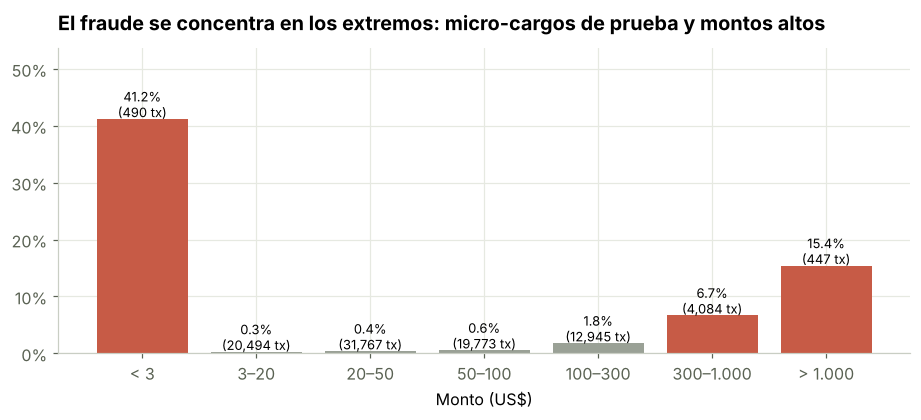

In [4]:
tramos = pd.cut(tx["monto_usd"], [0, 3, 20, 50, 100, 300, 1000, np.inf],
                labels=["< 3", "3–20", "20–50", "50–100", "100–300", "300–1.000", "> 1.000"])
t = tx.groupby(tramos, observed=True)["fraude"].agg(["mean", "size"])
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(t.index.astype(str), t["mean"], color=[ROJO if v > .02 else GRIS for v in t["mean"]])
for k, (v, n) in enumerate(zip(t["mean"], t["size"])): ax.text(k, v + .003, f"{v:.1%}\n({n:,} tx)", ha="center", fontsize=8.5)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.set_xlabel("Monto (US$)"); ax.set_ylim(0, t["mean"].max() * 1.3)
ax.set_title("El fraude se concentra en los extremos: micro-cargos de prueba y montos altos")
plt.show()
print(f"Fraudes de menos de US$ 3 (cargos de prueba): {(tx.loc[tx['fraude']==1, 'monto_usd'] < 3).mean():.0%} del total de fraudes")

## 2. Variables y partición temporal
Además de las columnas originales, creo variables que capturan **comportamiento anómalo**: el monto en
relación con el gasto habitual del cliente, si es de madrugada, si la cuenta es nueva y si es un micro-cargo.

**Partición por tiempo, no al azar:** entreno con enero–abril, ajusto el umbral con mayo y evalúo una sola
vez con junio. Así simulo lo que pasa en producción (el modelo siempre predice el futuro) y evito que
información de fechas posteriores "se filtre" al entrenamiento.

In [5]:
tx["log_monto"] = np.log1p(tx["monto_usd"])
tx["ratio_vs_habitual"] = tx["monto_usd"] / tx["gasto_medio_30d_usd"]
tx["madrugada"] = tx["hora"].between(0, 5)
tx["cuenta_nueva"] = tx["antiguedad_cuenta_dias"] < 60
tx["micro_cargo"] = tx["monto_usd"] < 3
tx["lejos_de_casa"] = tx["distancia_domicilio_km"] > 40

NUM = ["log_monto", "ratio_vs_habitual", "hora", "distancia_domicilio_km", "tx_ultimas_24h", "intentos_fallidos_previos",
       "antiguedad_cuenta_dias", "edad_titular", "gasto_medio_30d_usd"]
BIN = ["internacional", "dispositivo_nuevo", "madrugada", "cuenta_nueva", "micro_cargo", "lejos_de_casa"]
CAT = ["categoria_comercio", "canal"]
FEATS = NUM + BIN + CAT
tx[BIN] = tx[BIN].astype(int)

train = tx[tx["fecha_hora"] < "2025-05-01"]
valid = tx[(tx["fecha_hora"] >= "2025-05-01") & (tx["fecha_hora"] < "2025-06-01")]
test = tx[tx["fecha_hora"] >= "2025-06-01"]
pd.DataFrame({"período": ["ene–abr", "may", "jun"], "transacciones": [len(train), len(valid), len(test)],
              "fraudes": [train["fraude"].sum(), valid["fraude"].sum(), test["fraude"].sum()]},
             index=["entrenamiento", "validación", "prueba"])

,período,transacciones,fraudes
entrenamiento,ene–abr,59860,753
validación,may,15409,185
prueba,jun,14731,148


## 3. Comparación de modelos
Comparo cuatro alternativas sobre el mes de validación:
- **Regla actual** del negocio (monto > US$ 300, o internacional desde un dispositivo nuevo).
- **Regresión logística**: simple e interpretable.
- **Random forest**.
- **Gradient boosting** (`HistGradientBoostingClassifier`).

La métrica principal es la **precisión promedio (PR-AUC)**: resume qué tan bien el modelo pone los fraudes
arriba de la lista, que es justamente lo que necesita el equipo que revisa alertas. También reporto ROC-AUC.

In [6]:
pre_lin = ColumnTransformer([("num", StandardScaler(), NUM + BIN), ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])
pre_arb = ColumnTransformer([("num", "passthrough", NUM + BIN), ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])
modelos = {
    "Regresión logística": make_pipeline(pre_lin, LogisticRegression(max_iter=3000, class_weight="balanced", C=.5)),
    "Random forest": make_pipeline(pre_arb, RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)),
    "Gradient boosting": make_pipeline(pre_arb, HistGradientBoostingClassifier(learning_rate=.05, max_iter=350, max_leaf_nodes=24, l2_regularization=1.0, random_state=SEED)),
}
regla = lambda d: ((d["monto_usd"] > 300) | ((d["internacional"] == 1) & (d["dispositivo_nuevo"] == 1))).astype(float)

resultados, scores_valid = [], {}
r = regla(valid); scores_valid["Regla actual"] = r
resultados.append({"modelo": "Regla actual", "PR-AUC": average_precision_score(valid["fraude"], r), "ROC-AUC": roc_auc_score(valid["fraude"], r)})
for nombre, m in modelos.items():
    m.fit(train[FEATS], train["fraude"])
    p = m.predict_proba(valid[FEATS])[:, 1]; scores_valid[nombre] = p
    resultados.append({"modelo": nombre, "PR-AUC": average_precision_score(valid["fraude"], p), "ROC-AUC": roc_auc_score(valid["fraude"], p)})
resultados = pd.DataFrame(resultados).set_index("modelo")
resultados

,PR-AUC,ROC-AUC
modelo,,
Regla actual,0.029,0.628
Regresión logística,0.407,0.931
Random forest,0.467,0.918
Gradient boosting,0.512,0.929


Mejor modelo: Gradient boosting. PR-AUC 0.51 contra 0.03 de la regla actual.


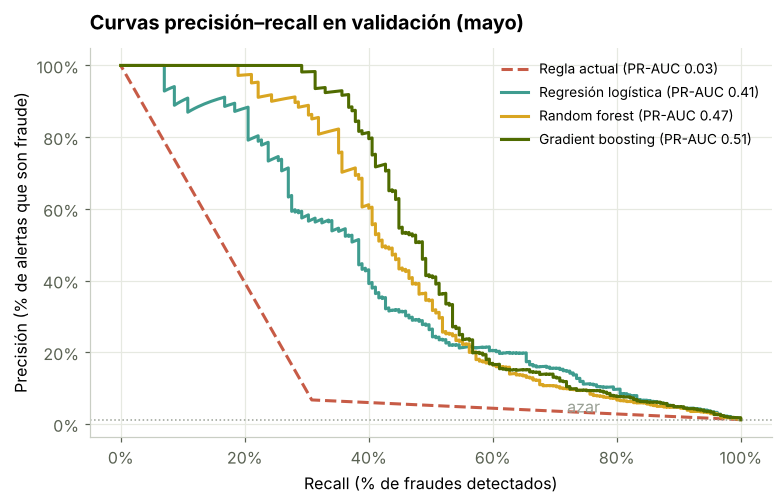

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.6))
colores = {"Regla actual": ROJO, "Regresión logística": AZUL, "Random forest": OCRE, "Gradient boosting": VERDE}
for nombre, s in scores_valid.items():
    pr, rc, _ = precision_recall_curve(valid["fraude"], s)
    est = "--" if nombre == "Regla actual" else "-"
    ax.plot(rc, pr, est, color=colores[nombre], lw=2, label=f"{nombre} (PR-AUC {resultados.loc[nombre, 'PR-AUC']:.2f})")
ax.axhline(valid["fraude"].mean(), color=GRIS, lw=1, ls=":"); ax.text(.72, valid["fraude"].mean() + .02, "azar", color=GRIS)
ax.set_xlabel("Recall (% de fraudes detectados)"); ax.set_ylabel("Precisión (% de alertas que son fraude)")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_title("Curvas precisión–recall en validación (mayo)"); ax.legend(loc="upper right", fontsize=9)
plt.show()
mejor = resultados.drop("Regla actual")["PR-AUC"].idxmax()
print(f"Mejor modelo: {mejor}. PR-AUC {resultados.loc[mejor, 'PR-AUC']:.2f} contra {resultados.loc['Regla actual', 'PR-AUC']:.2f} de la regla actual.")

## 4. Umbral óptimo según costo
El modelo da una probabilidad; el negocio necesita decidir **a partir de qué valor se genera una alerta**.
Elijo el umbral que minimiza el costo total en validación con estos supuestos:

| Error / acción | Costo |
|---|---|
| Fraude no detectado | el monto del fraude + US$ 15 de gestión del contracargo |
| Cada alerta revisada por un analista | US$ 3 |
| Alerta sobre un cliente legítimo (falso positivo) | US$ 5 adicionales por fricción y riesgo de baja |

Los supuestos se pueden cambiar en una sola celda; en el dashboard hay un control para explorar el umbral.

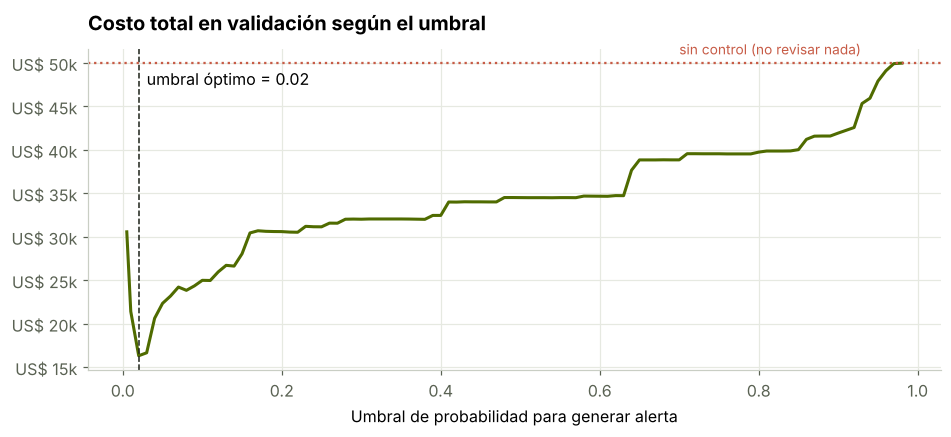

,alertas,precision,recall,fraudes_detectados,falsos_positivos,fraudes_perdidos,monto_detectado,monto_perdido,costo_total
umbral,,,,,,,,,
0.020,1242,0.107,0.719,133,1109,52,"40,948.190","6,273.830","16,324.830"
0.100,250,0.380,0.514,95,155,90,"25,096.430","22,125.590","25,000.590"
0.200,139,0.597,0.449,83,56,102,"18,843.590","28,378.430","30,605.430"
0.300,102,0.745,0.411,76,26,109,"17,262.600","29,959.420","32,030.420"
0.500,82,0.854,0.378,70,12,115,"14,736.380","32,485.640","34,516.640"
0.700,65,0.938,0.330,61,4,124,"10,439.920","36,782.100","38,857.100"


In [8]:
C_GESTION, C_REVISION, C_FRICCION = 15, 3, 5

def costo(y, monto, alerta):
    fn = (y == 1) & ~alerta; fp = (y == 0) & alerta
    return (monto[fn] + C_GESTION).sum() + C_REVISION * alerta.sum() + C_FRICCION * fp.sum()

def evaluar(y, monto, score, umbral):
    a = score >= umbral; tp = int(((y == 1) & a).sum()); fp = int(((y == 0) & a).sum()); fn = int(((y == 1) & ~a).sum())
    return {"umbral": umbral, "alertas": int(a.sum()), "precision": tp / max(1, tp + fp), "recall": tp / max(1, tp + fn),
            "fraudes_detectados": tp, "falsos_positivos": fp, "fraudes_perdidos": fn,
            "monto_detectado": float(monto[(y == 1) & a].sum()), "monto_perdido": float(monto[(y == 1) & ~a].sum()),
            "costo_total": float(costo(y, monto, a))}

yv, mv = valid["fraude"].values, valid["monto_usd"].values
umbrales = np.round(np.r_[.005, np.arange(.01, .99, .01)], 3)
curva_v = pd.DataFrame([evaluar(yv, mv, scores_valid[mejor], u) for u in umbrales])
u_opt = float(curva_v.loc[curva_v["costo_total"].idxmin(), "umbral"])
sin_modelo = costo(yv, mv, np.zeros(len(yv), bool))

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(curva_v["umbral"], curva_v["costo_total"], color=VERDE, lw=2)
ax.axvline(u_opt, color=TINTA, ls="--", lw=1); ax.text(u_opt + .01, curva_v["costo_total"].max() * .95, f"umbral óptimo = {u_opt:.2f}")
ax.axhline(sin_modelo, color=ROJO, ls=":", lw=1.5); ax.text(.7, sin_modelo * 1.02, "sin control (no revisar nada)", color=ROJO, fontsize=9)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"US$ {v/1000:.0f}k"))
ax.set_xlabel("Umbral de probabilidad para generar alerta"); ax.set_title("Costo total en validación según el umbral")
plt.show()
curva_v.loc[curva_v["umbral"].isin([.1, .2, .3, u_opt, .5, .7])].set_index("umbral")

El umbral óptimo por probabilidad queda muy bajo: como revisar una alerta es barato frente a perder un
fraude, conviene alertar mucho. Pero un umbral único trata igual a un cargo de US$ 2 y a uno de US$ 900.

### 4.2 Decisión por pérdida esperada
Una regla mejor usa el **monto** de cada transacción: genero alerta solo si lo que espero perder supera lo
que cuesta revisar.

$$\text{alertar si}\quad p \cdot (\text{monto} + 15) \;>\; 3 + (1 - p) \cdot 5$$

Esta regla solo es válida si las probabilidades del modelo están **bien calibradas**, es decir, si
"10 % de riesgo" significa que 1 de cada 10 de esos casos es fraude. Lo verifico primero.

Los puntos siguen la diagonal: las probabilidades son confiables para calcular pérdidas esperadas.
Validación: costo con umbral óptimo US$ 16,325 · con pérdida esperada US$ 14,752 · regla actual US$ 19,202


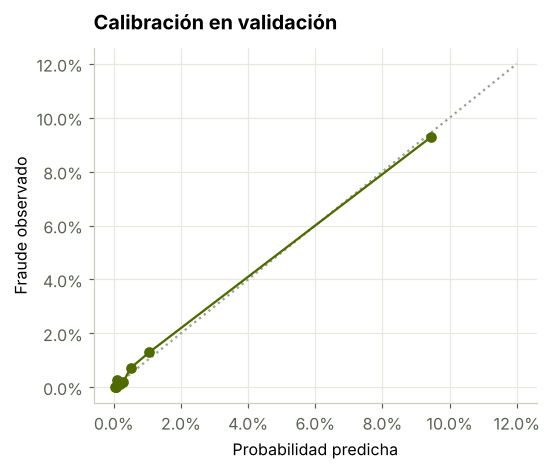

In [9]:
from sklearn.calibration import calibration_curve
frac, media = calibration_curve(yv, scores_valid[mejor], n_bins=10, strategy="quantile")
fig, ax = plt.subplots(figsize=(5.2, 4.2))
ax.plot([0, .12], [0, .12], ls=":", color=GRIS); ax.plot(media, frac, "o-", color=VERDE)
ax.set_xlabel("Probabilidad predicha"); ax.set_ylabel("Fraude observado")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_title("Calibración en validación"); plt.show()
print("Los puntos siguen la diagonal: las probabilidades son confiables para calcular pérdidas esperadas.")

def alerta_pe(p, monto):
    return p * (monto + C_GESTION) > C_REVISION + (1 - p) * C_FRICCION

pe_v = alerta_pe(scores_valid[mejor], mv)
print(f"Validación: costo con umbral óptimo US$ {curva_v['costo_total'].min():,.0f} · "
      f"con pérdida esperada US$ {costo(yv, mv, pe_v):,.0f} · regla actual US$ {costo(yv, mv, regla(valid).values > .5):,.0f}")

## 5. Resultado final en datos nunca vistos (junio)
Con todo decidido en validación, evalúo **una sola vez** en junio: sin control, la regla actual, el modelo
con umbral único y el modelo con decisión por pérdida esperada.

In [10]:
final = modelos[mejor]
pt = final.predict_proba(test[FEATS])[:, 1]
yt, mt = test["fraude"].values, test["monto_usd"].values

def evaluar_alerta(y, monto, a):
    tp = int(((y == 1) & a).sum()); fp = int(((y == 0) & a).sum()); fn = int(((y == 1) & ~a).sum())
    return {"alertas": int(a.sum()), "precision": tp / max(1, tp + fp), "recall": tp / max(1, tp + fn),
            "fraudes_detectados": tp, "falsos_positivos": fp, "fraudes_perdidos": fn,
            "monto_detectado": float(monto[(y == 1) & a].sum()), "monto_perdido": float(monto[(y == 1) & ~a].sum()),
            "%_monto_detectado": float(monto[(y == 1) & a].sum() / monto[y == 1].sum()), "costo_total": float(costo(y, monto, a))}

res_nada = evaluar_alerta(yt, mt, np.zeros(len(yt), bool))
res_regla = evaluar_alerta(yt, mt, regla(test).values > .5)
res_umbral = evaluar_alerta(yt, mt, pt >= u_opt)
res_modelo = evaluar_alerta(yt, mt, alerta_pe(pt, mt))
comp = pd.DataFrame({"Sin control": res_nada, "Regla actual": res_regla, f"Modelo · umbral {u_opt:.3g}": res_umbral,
                     "Modelo · pérdida esperada": res_modelo}).T
comp

,alertas,precision,recall,fraudes_detectados,falsos_positivos,fraudes_perdidos,monto_detectado,monto_perdido,%_monto_detectado,costo_total
Sin control,0.000,0.000,0.000,0.000,0.000,148.000,0.000,"44,343.070",0.000,"46,563.070"
Regla actual,785.000,0.073,0.385,57.000,728.000,91.000,"36,894.510","7,448.560",0.832,"14,808.560"
Modelo · umbral 0.02,"1,170.000",0.103,0.811,120.000,"1,050.000",28.000,"39,829.720","4,513.350",0.898,"13,693.350"
Modelo · pérdida esperada,723.000,0.145,0.709,105.000,618.000,43.000,"38,920.930","5,422.140",0.878,"11,326.140"


PR-AUC en junio: 0.57 · ROC-AUC: 0.958
Con pérdida esperada, el modelo detecta el 71% de los fraudes y el 88% del monto (la regla: 39% y 83%) con 723 alertas (la regla: 785).
Precisión de las alertas: modelo 15% · regla 7%
Costo de junio: modelo US$ 11,326 · regla US$ 14,809 → ahorro de US$ 3,482 en el mes (24% menos), ~US$ 41,789 al año.


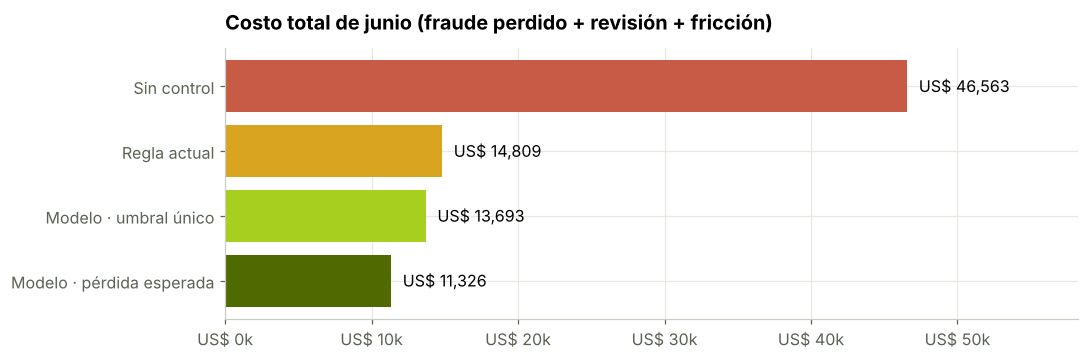

In [11]:
ahorro_regla = res_regla["costo_total"] - res_modelo["costo_total"]
print(f"PR-AUC en junio: {average_precision_score(yt, pt):.2f} · ROC-AUC: {roc_auc_score(yt, pt):.3f}")
print(f"Con pérdida esperada, el modelo detecta el {res_modelo['recall']:.0%} de los fraudes y el {res_modelo['%_monto_detectado']:.0%} del monto "
      f"(la regla: {res_regla['recall']:.0%} y {res_regla['%_monto_detectado']:.0%}) con {res_modelo['alertas']:,} alertas (la regla: {res_regla['alertas']:,}).")
print(f"Precisión de las alertas: modelo {res_modelo['precision']:.0%} · regla {res_regla['precision']:.0%}")
print(f"Costo de junio: modelo US$ {res_modelo['costo_total']:,.0f} · regla US$ {res_regla['costo_total']:,.0f} → "
      f"ahorro de US$ {ahorro_regla:,.0f} en el mes ({ahorro_regla / res_regla['costo_total']:.0%} menos), ~US$ {ahorro_regla*12:,.0f} al año.")

fig, ax = plt.subplots(figsize=(10, 3.2))
nombres = ["Sin control", "Regla actual", f"Modelo · umbral único", "Modelo · pérdida esperada"]
vals = [res_nada["costo_total"], res_regla["costo_total"], res_umbral["costo_total"], res_modelo["costo_total"]]
ax.barh(nombres[::-1], vals[::-1], color=[VERDE, LIMA, OCRE, ROJO])
for i, v in enumerate(vals[::-1]): ax.text(v + 800, i, f"US$ {v:,.0f}", va="center")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"US$ {v/1000:.0f}k")); ax.set_xlim(0, max(vals) * 1.25)
ax.set_title("Costo total de junio (fraude perdido + revisión + fricción)")
plt.show()

## 6. ¿Qué mira el modelo?
Uso **importancia por permutación** en junio: mezclo los valores de cada variable y mido cuánto cae la
PR-AUC. Cuanto más cae, más depende el modelo de esa variable.

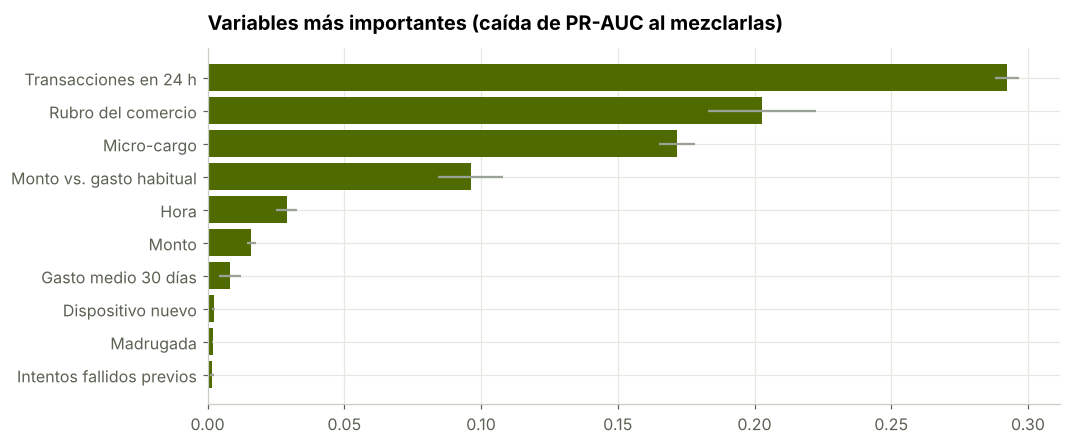

,importancia,desvio
Transacciones en 24 h,0.292,0.005
Rubro del comercio,0.203,0.020
Micro-cargo,0.172,0.007
Monto vs. gasto habitual,0.096,0.012
Hora,0.029,0.004
Monto,0.016,0.002
Gasto medio 30 días,0.008,0.004
Dispositivo nuevo,0.002,0.001
Madrugada,0.002,0.000
Intentos fallidos previos,0.002,0.001


In [12]:
pi = permutation_importance(final, test[FEATS], yt, scoring="average_precision", n_repeats=5, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"importancia": pi.importances_mean, "desvio": pi.importances_std}, index=FEATS).sort_values("importancia", ascending=False)
NOMBRES = {"log_monto": "Monto", "ratio_vs_habitual": "Monto vs. gasto habitual", "hora": "Hora", "distancia_domicilio_km": "Distancia al domicilio",
           "tx_ultimas_24h": "Transacciones en 24 h", "intentos_fallidos_previos": "Intentos fallidos previos", "antiguedad_cuenta_dias": "Antigüedad de la cuenta",
           "edad_titular": "Edad del titular", "gasto_medio_30d_usd": "Gasto medio 30 días", "internacional": "Internacional",
           "dispositivo_nuevo": "Dispositivo nuevo", "madrugada": "Madrugada", "cuenta_nueva": "Cuenta nueva", "micro_cargo": "Micro-cargo",
           "lejos_de_casa": "Lejos de casa", "categoria_comercio": "Rubro del comercio", "canal": "Canal"}
imp.index = imp.index.map(NOMBRES)
top = imp.head(10)[::-1]
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.barh(top.index, top["importancia"], xerr=top["desvio"], color=VERDE, ecolor=GRIS)
ax.set_title("Variables más importantes (caída de PR-AUC al mezclarlas)")
plt.show()
imp.head(10)

## 7. Conclusiones
**Lo que muestran los datos**
1. **El fraude deja patrones claros, pero ninguna señal alcanza sola.** Las ráfagas de transacciones (6 o más en 24 horas) multiplican por 16 la tasa de fraude. La madrugada, los rubros Viajes y Electrónica, los dispositivos nuevos y los micro-cargos de prueba (19 % de los fraudes) también la suben.
2. **La regla actual casi no ordena el riesgo** (PR-AUC 0,03): marca todo lo que supera US$ 300, así que genera muchas alertas falsas y deja pasar el 61 % de los fraudes, aunque sean de monto chico.
3. **Gradient boosting es el mejor modelo:** PR-AUC 0,57 y ROC-AUC 0,96 en junio, un mes que el modelo nunca vio. Supera a la regresión logística y al random forest, y sus probabilidades están bien calibradas.
4. **El umbral importa tanto como el modelo.** Con un umbral único por probabilidad, el ahorro frente a la regla es chico (8 %). Al decidir por **pérdida esperada**, que tiene en cuenta el monto de cada transacción, el costo de junio baja de US$ 14.800 a US$ 11.300 (**-24 %**, unos US$ 42.000 al año). Además se generan menos alertas (723 contra 785) y se detecta el 88 % del monto fraudulento.
5. **Las alertas son el doble de precisas:** 15 % de las alertas del modelo son fraude, contra 7 % de la regla. Eso significa menos clientes legítimos bloqueados y menos trabajo inútil para el equipo de revisión.

**Recomendaciones**
- **Reemplazar la regla fija por el modelo con decisión por pérdida esperada**, empezando en modo sombra (el modelo puntúa pero no bloquea) durante 2 a 4 semanas, para confirmar el ahorro con datos reales.
- **Bloqueo automático para ráfagas con micro-cargos:** es el patrón más claro de prueba de tarjetas robadas.
- **Monitorear el modelo todos los meses:** PR-AUC, calibración y cambios en la distribución de las variables. El fraude cambia de táctica y el modelo tiene que reentrenarse.
- **Validar los costos con el negocio:** la regla de pérdida esperada depende de cuánto cuesta revisar y cuánto cuesta la fricción. Si esos números cambian, cambia automáticamente el criterio de alerta.

**Limitaciones:** la etiqueta de fraude llega con demora (los contracargos se confirman semanas después). En producción hay que tenerlo en cuenta para el reentrenamiento y para no evaluar sobre etiquetas incompletas.

In [13]:
pr_pts = {}
for nombre, s in [("Regla actual", regla(test).values)] + [(n, m.predict_proba(test[FEATS])[:, 1]) for n, m in modelos.items()]:
    p, r_, _ = precision_recall_curve(yt, s)
    k = np.linspace(0, len(p) - 1, min(len(p), 120)).astype(int)
    pr_pts[nombre] = {"r": np.round(r_[k], 4).tolist(), "p": np.round(p[k], 4).tolist(), "ap": float(average_precision_score(yt, s))}
curva_t = pd.DataFrame([evaluar(yt, mt, pt, u) for u in umbrales])
cal = {"pred": [float(x) for x in media], "obs": [float(x) for x in frac]}
out = {
    "base": {"n": int(len(tx)), "fraudes": int(tx["fraude"].sum()), "tasa": float(tx["fraude"].mean()), "monto_fraude": float(tx.loc[tx["fraude"] == 1, "monto_usd"].sum()),
             "n_test": int(len(test)), "fraudes_test": int(yt.sum())},
    "hora": [float(x) for x in h.values], "tramos": {"labels": [str(x) for x in t.index], "tasa": [float(x) for x in t["mean"]], "n": [int(x) for x in t["size"]]}, "rubro": [{"rubro": k, "tasa": float(v)} for k, v in c.sort_values(ascending=False).items()],
    "segmentos": seg.reset_index(names="segmento").to_dict("records"),
    "modelos": resultados.reset_index().to_dict("records"), "mejor": mejor, "pr": pr_pts,
    "umbral_opt": u_opt, "curva": curva_t.to_dict("list"),
    "comparacion": {"nada": res_nada, "regla": res_regla, "umbral": res_umbral, "modelo": res_modelo}, "calibracion": cal,
    "costos": {"gestion": C_GESTION, "revision": C_REVISION, "friccion": C_FRICCION},
    "importancia": imp.head(10).reset_index(names="variable").to_dict("records"),
    "test_metricas": {"ap": float(average_precision_score(yt, pt)), "auc": float(roc_auc_score(yt, pt))},
}
dest = Path("../../fraude"); dest.mkdir(parents=True, exist_ok=True)
(dest / "data.json").write_text(json.dumps(out, ensure_ascii=False, default=float).replace("NaN", "null"))
print("Datos del dashboard exportados:", dest / "data.json")

Datos del dashboard exportados: ../../fraude/data.json
